# Evaluator: Visibility Timing

This notebook evaluates the refactored `Visibility_timing.py` experiment with a single solver type. Sender and receiver crowds use bounded `knowledge_breadth`; all outcome measures concern the **receiver** crowd.

The principal figures show best-solution rank, pairwise solution diversity, and adopted-solution fitness across visibility start. Each outcome is plotted as either an **average across all K values** or **separate curves for each K**. Supplementary figures examine fitness, uniqueness, adoption trajectories, and start-by-K heatmaps.

**Input:** six pickle output families produced by `Visibility_timing.py`. No simulation rerun is required. The notebook saves **PNG figures only**, not CSV files.

## 1. Configuration and methods

- Experiment settings below: `N=18`, `K=9, ..., 17`, `agent_num=200` in each crowd, `knowledge_breadth=12`, `search_iteration=300`, `visibility_extent=1.0`, and `visibility_interval=10`.
- **Visibility start** is the zero-based search-period index of the first disclosure. Visibility then recurs every `visibility_interval` periods; a start of 0 means disclosure after the first local search step.
- Each saved scalar is already averaged across 400 landscape repetitions for each `(start, K)`; the overall plots average equally over **all** K values in `K_list`.
- Saved results lack repetition-level variation, so confidence intervals and significance tests cannot be calculated here.
- `adopted_solution_fitness` measures the mean true fitness of adopted solutions, conditional on adoption; when no adoption occurs it is undefined (`NaN`), not zero. Its time trajectory is a cumulative mean. Later starts have fewer visibility events.

**Edit `result_folder` to point to your pickle outputs.** Figures are saved in its `visibility_timing_figures` subfolder.

In [1]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Matched to the earlier evaluator notebook.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91']


def format_axis(ax):
    """Keep the formatting of the provided evaluator."""
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.5)
    ax.tick_params(axis='both', labelsize=11)
    return ax


def safe_nanmean(values, axis=None):
    """Ignore structurally undefined adoption values, retaining all-NaN as NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)


In [2]:
# =========================
# Experiment configuration — same as Visibility_timing.py
# =========================
N = 18
agent_num = 200
knowledge_breadth = 12
landscape_iteration = 400  # Documentation only; averages were already computed upstream.
search_iteration = 300
K_list = list(range(9, N))
visibility_extent = 1.0
visibility_start_list = [0, 10, 20, 30, 40, 50, 75, 100, 200, 250, 260, 270, 280, 290]
visibility_interval = 10

# Change this to the folder containing your new pickle outputs, if auto-detection fails.
result_folder = "/Volumes/T7/data/gst-1010-26/ISR_Visibility_2/Timing"  # e.g., Path('/Volumes/T7/data/your-new-experiment')

# Set to False to explore results without saving any figures.
save_figures = True
strict_loading = True  # Set False to view partial results from an unfinished run.

candidate_folders = [Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']
expected_example = (f'visibility_start_{visibility_start_list[0]}_interval_{visibility_interval}'
                    f'_breakthrough_rank_across_K_size_{agent_num}')

if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / expected_example).is_file()), Path.cwd())
result_folder = Path(result_folder).expanduser()
figure_folder = result_folder / 'visibility_timing_figures'
if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)

print('Result folder:', result_folder)
print('Output folder:', figure_folder)
print('Example expected file:', expected_example)
print('Folder exists:', result_folder.exists())

Result folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_2/Timing
Output folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_2/Timing/visibility_timing_figures
Example expected file: visibility_start_0_interval_10_breakthrough_rank_across_K_size_200
Folder exists: True


## 2. Load and validate the six outcome families

Files follow the timing experiment's name scheme, with **`visibility_start`** as the running parameter and a fixed visibility interval:

`visibility_start_{start}_interval_{interval}_{DV}_across_K_size_{agent_num}`

The five scalar outcomes load as arrays of shape `(start, K)`. Adoption-fitness trajectories have **different lengths across starts** because visibility begins at different periods; they are padded with `NaN` to a common shape `(start, K, max visibility events)` only for convenient indexing. The loader validates each start's actual event count, preserves undefined values as `NaN`, and reports absent files without shifting rows out of alignment.

In [3]:
scalar_dvs = [
    'breakthrough_rank',
    'breakthrough_fitness',
    'pairwise_diversity',
    'unique_solution_count',
    'adopted_solution_fitness',
]
trajectory_dv = 'adopted_solution_fitness_across_time'
events_by_start = {start: len(range(start, search_iteration, visibility_interval))
                   for start in visibility_start_list}
expected_events = max(events_by_start.values())


def result_file(start, dv):
    filename = (f'visibility_start_{start}_interval_{visibility_interval}_'
                f'{dv}_across_K_size_{agent_num}')
    return result_folder / filename


def load_pickle(path):
    with open(path, 'rb') as infile:
        return pickle.load(infile)


def load_visibility_timing_results(strict=True):
    n_start = len(visibility_start_list)
    n_K = len(K_list)
    data = {dv: np.full((n_start, n_K), np.nan) for dv in scalar_dvs}
    data[trajectory_dv] = np.full((n_start, n_K, expected_events), np.nan)
    missing_files = []
    invalid_files = []

    for i, start in enumerate(visibility_start_list):
        for dv in scalar_dvs + [trajectory_dv]:
            path = result_file(start, dv)
            if not path.is_file():
                missing_files.append(path.name)
                continue
            try:
                values = np.asarray(load_pickle(path), dtype=float)
            except (OSError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                invalid_files.append((path.name, str(exc)))
                continue
            shape = (n_K, events_by_start[start]) if dv == trajectory_dv else (n_K,)
            if values.shape != shape:
                invalid_files.append((path.name, f'got {values.shape}; expected {shape}'))
                continue
            if dv == trajectory_dv:
                data[dv][i, :, :events_by_start[start]] = values
            else:
                data[dv][i] = values

    print(f'Files loaded: {n_start * 6 - len(missing_files) - len(invalid_files)} / {n_start * 6}')
    print('Array shapes:', {dv: value.shape for dv, value in data.items()})

    if missing_files:
        print(f'\nMissing files ({len(missing_files)}):')
        for filename in missing_files[:12]:
            print('  ', filename)
        if len(missing_files) > 12:
            print('  ...')
    if invalid_files:
        print(f'\nInvalid files ({len(invalid_files)}):')
        for name, issue in invalid_files[:12]:
            print('  ', name, ':', issue)

    if strict and (missing_files or invalid_files):
        raise FileNotFoundError(
            'Missing/invalid visibility-timing results. Edit result_folder, agent_num, '
            'visibility_interval, the start grid, or set strict_loading=False '
            'for incomplete runs. First expected file: ' + str(result_file(visibility_start_list[0], 'breakthrough_rank'))
        )
    if not any(np.isfinite(data[dv]).any() for dv in scalar_dvs):
        raise FileNotFoundError('No valid scalar pickle outputs found in ' + str(result_folder))
    return data


data = load_visibility_timing_results(strict=strict_loading)

Files loaded: 84 / 84
Array shapes: {'breakthrough_rank': (14, 9), 'breakthrough_fitness': (14, 9), 'pairwise_diversity': (14, 9), 'unique_solution_count': (14, 9), 'adopted_solution_fitness': (14, 9), 'adopted_solution_fitness_across_time': (14, 9, 30)}


In [17]:
# =========================
# Data checks and long-form details
# =========================
checks = {
    'breakthrough_rank': (1, 2 ** N),
    'breakthrough_fitness': (0, 1),
    'pairwise_diversity': (0, 1),
    'unique_solution_count': (1, agent_num),
    'adopted_solution_fitness': (0, 1),
}
for dv, (minimum, maximum) in checks.items():
    finite = data[dv][np.isfinite(data[dv])]
    outside = np.count_nonzero((finite < minimum - 1e-8) | (finite > maximum + 1e-8))
    print(f'{dv:29s} finite={finite.size:3d} / {data[dv].size:3d}; outside expected range={outside}')

# The trajectory's final cumulative mean should match the scalar adoption-quality
# measure for each (start, K), up to floating-point differences.
last_trajectory = np.array([data[trajectory_dv][i, :, events_by_start[start] - 1]
                            for i, start in enumerate(visibility_start_list)])
both_defined = np.isfinite(last_trajectory) & np.isfinite(data['adopted_solution_fitness'])
if both_defined.any():
    gap = np.max(np.abs(last_trajectory[both_defined] - data['adopted_solution_fitness'][both_defined]))
    print('Max discrepancy: final trajectory vs. scalar adoption quality =', round(float(gap), 12))

rows = []
for i, start in enumerate(visibility_start_list):
    for j, K in enumerate(K_list):
        row = {'visibility_start': start, 'K': K}
        for dv in scalar_dvs:
            row[dv] = data[dv][i, j]
        rows.append(row)

detailed_results = pd.DataFrame(rows)
print('\nDetailed data preview (one observation per start × K):')
# display(detailed_results.head(12).round(4))

breakthrough_rank             finite=126 / 126; outside expected range=0
breakthrough_fitness          finite=126 / 126; outside expected range=0
pairwise_diversity            finite=126 / 126; outside expected range=0
unique_solution_count         finite=126 / 126; outside expected range=0
adopted_solution_fitness      finite=126 / 126; outside expected range=0
Max discrepancy: final trajectory vs. scalar adoption quality = 0.0

Detailed data preview (one observation per start × K):


## 3. Main results: visibility timing

The overall curves average each outcome equally across **all K values** in `K_list`. The adjacent by-K figures show heterogeneity across landscape complexity. Lines join the sampled visibility starts in their actual numerical order, including the finer grid near the end of search.

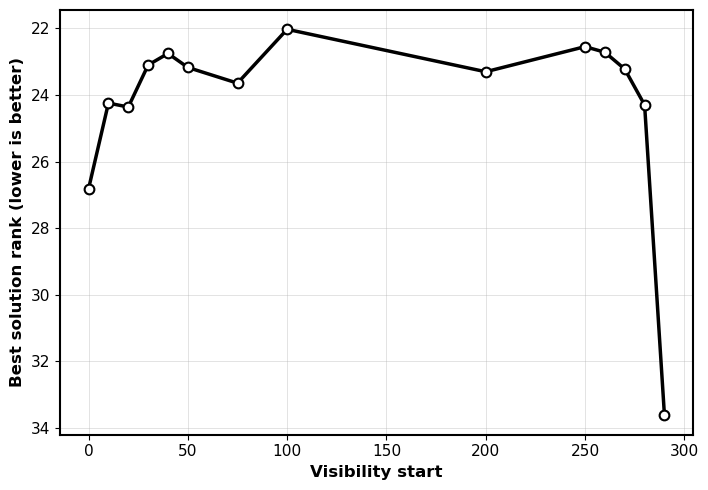

In [5]:
# Best solution rank across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
x = np.asarray(visibility_start_list)
y_rank = safe_nanmean(data['breakthrough_rank'], axis=1)
ax.plot(x, y_rank, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.invert_yaxis()  # Rank 1 is best; invert so a better rank is visually higher.
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Breakthrough_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

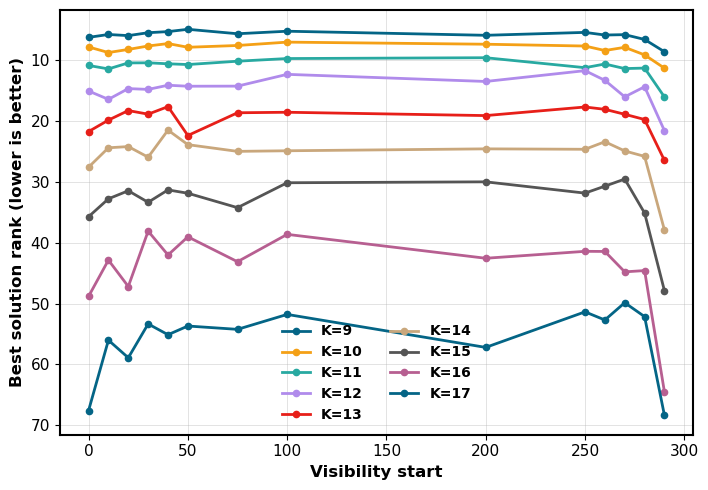

In [6]:
# Best solution rank across visibility start (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(visibility_start_list, data['breakthrough_rank'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.invert_yaxis()
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Breakthrough_by_K_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

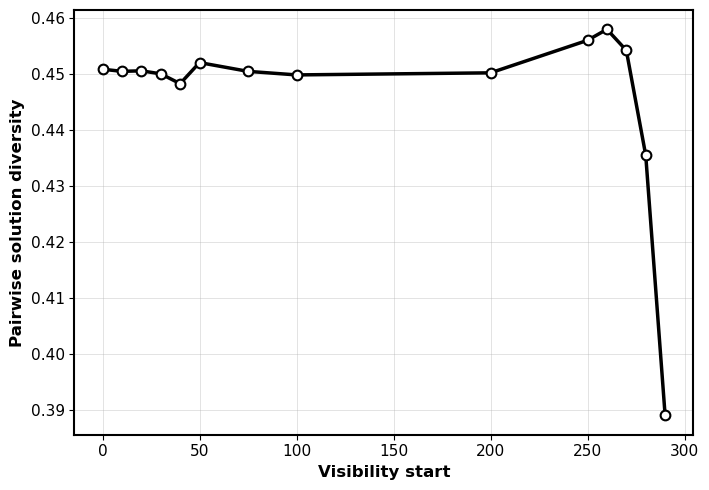

In [7]:
# Pairwise diversity across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_diversity = safe_nanmean(data['pairwise_diversity'], axis=1)
ax.plot(x, y_diversity, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Pairwise_diversity_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

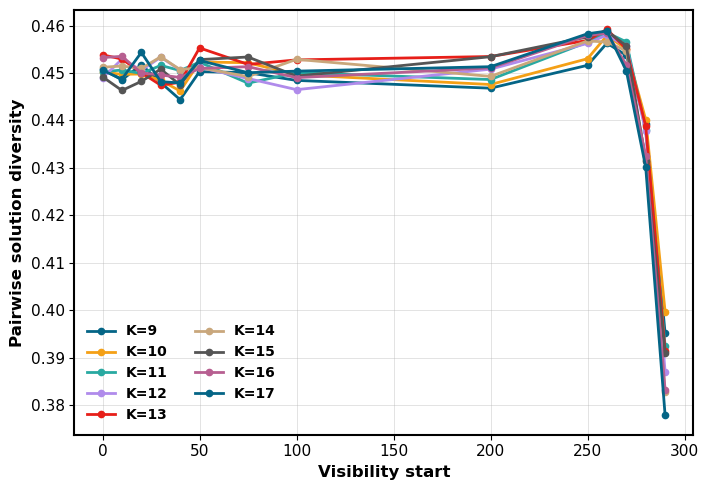

In [8]:
# Pairwise diversity across visibility start (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(visibility_start_list, data['pairwise_diversity'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Pairwise_diversity_by_K_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

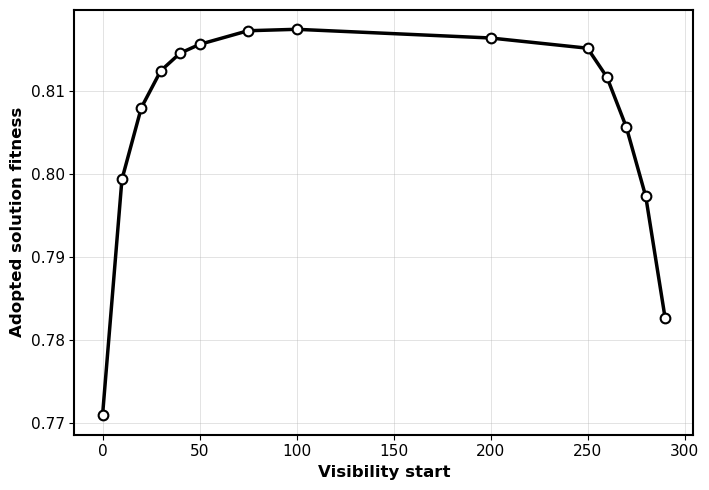

In [9]:
# Adopted solution fitness across visibility start (average across K).
# Undefined outcomes (when no adoption occurs) stay NaN and are not shown as zero.
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_adopted = safe_nanmean(data['adopted_solution_fitness'], axis=1)
ax.plot(x, y_adopted, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_quality_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

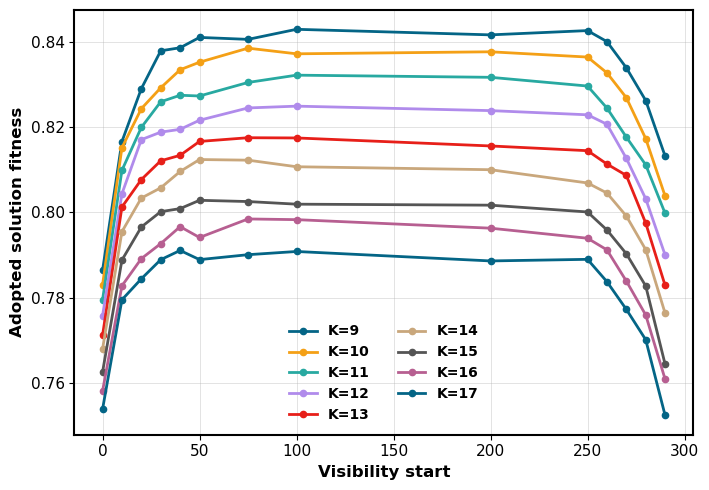

In [10]:
# Adopted solution fitness across visibility start (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(visibility_start_list, data['adopted_solution_fitness'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_fitness_by_K_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 4. Additional outcomes

`breakthrough_fitness` is the highest final receiver-solution fitness within a repetition; `breakthrough_rank` is the best final receiver solution's rank in the landscape. These are related but distinct summary scales. `unique_solution_count` captures the number of distinct final receiver solutions, whereas **pairwise diversity** captures how different those solutions are, even when uniqueness coincides.

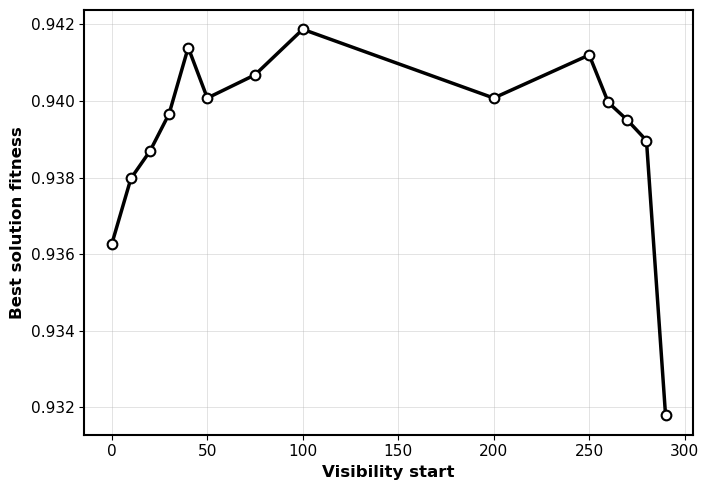

In [11]:
# Best solution fitness across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_fitness = safe_nanmean(data['breakthrough_fitness'], axis=1)
ax.plot(x, y_fitness, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Best_solution_fitness_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

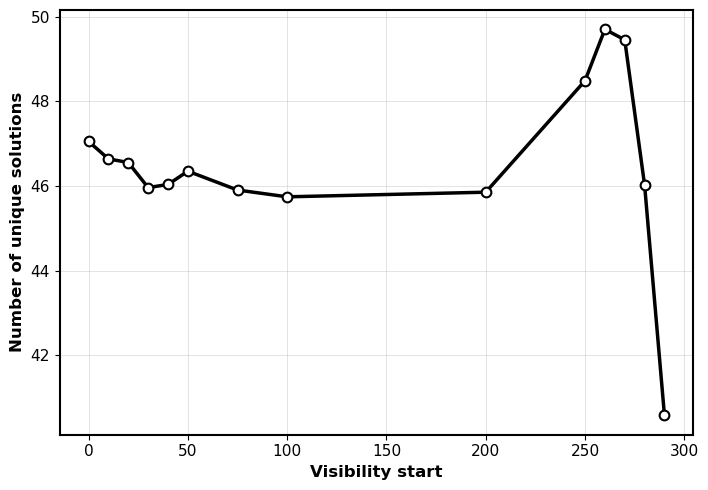

In [12]:
# Unique solution count across visibility start (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_unique = safe_nanmean(data['unique_solution_count'], axis=1)
ax.plot(x, y_unique, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
ax.set_ylabel('Number of unique solutions', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Unique_solution_count_across_visibility_start.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 5. Adoption-quality trajectories across search time

Set `trajectory_visibility_start` to any sampled visibility start. The horizontal axis gives actual **one-based search periods** when visibility occurs (for example, `1, 11, ..., 291` at start 0 and interval 10). Values are **cumulative mean fitness of adopted solutions through that event**, not fitness of only that period's adoptions or mean fitness of all receiver solutions. The first figure averages all K values; the second plots every K separately.

In [13]:
trajectory_visibility_start = 0  # Change to any entry in visibility_start_list.
if trajectory_visibility_start not in visibility_start_list:
    raise ValueError('trajectory_visibility_start must appear in visibility_start_list.')
trajectory_index = visibility_start_list.index(trajectory_visibility_start)
n_events = events_by_start[trajectory_visibility_start]
trajectory_periods = trajectory_visibility_start + 1 + np.arange(n_events) * visibility_interval
trajectory_by_K = data[trajectory_dv][trajectory_index, :, :n_events]  # (K, visibility event)
print('Trajectory start:', trajectory_visibility_start)
print('Visibility events:', len(trajectory_periods), '| last search period:', trajectory_periods[-1])
print('Defined trajectory entries:', np.isfinite(trajectory_by_K).sum(), '/', trajectory_by_K.size)

Trajectory start: 0
Visibility events: 30 | last search period: 291
Defined trajectory entries: 270 / 270


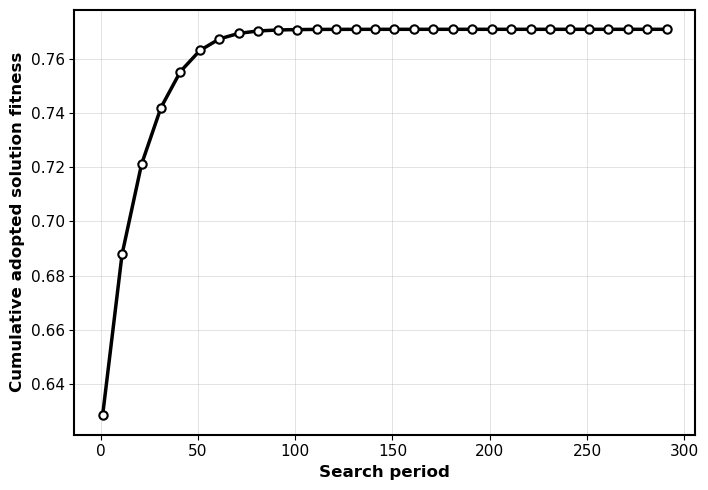

In [14]:
# Cumulative adopted solution fitness across search periods (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
trajectory_mean = safe_nanmean(trajectory_by_K, axis=0)
ax.plot(trajectory_periods, trajectory_mean, marker='o', linewidth=2.5,
        markersize=6, color='k', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_across_search_periods_start_{trajectory_visibility_start:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

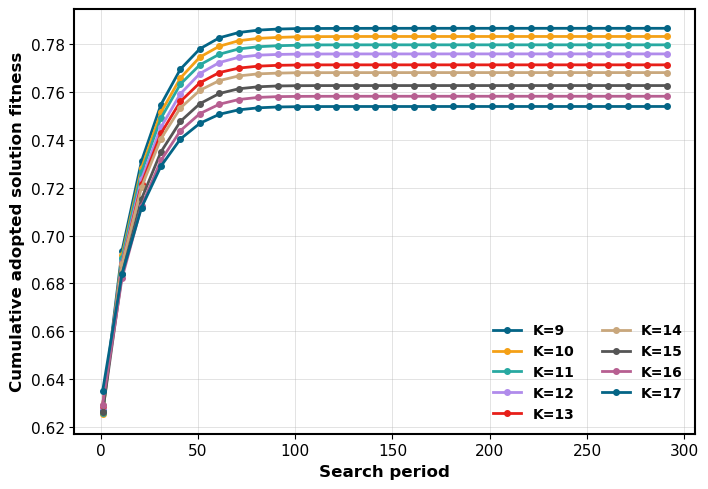

In [15]:
# Cumulative adopted solution fitness across search periods (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(trajectory_periods, trajectory_by_K[j], marker='o',
            linewidth=2.0, markersize=4, color=K_colors[j % len(K_colors)],
            label=f'K={K}')
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_by_K_across_search_periods_start_{trajectory_visibility_start:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 6. Visibility timing × landscape complexity

These heatmaps display the underlying saved `(start, K)` averages without pooling across `K`. `NaN` cells remain blank, especially for adoption quality when no adoption occurs. They help diagnose whether an overall trend is stable or masks heterogeneous responses across landscape complexity.

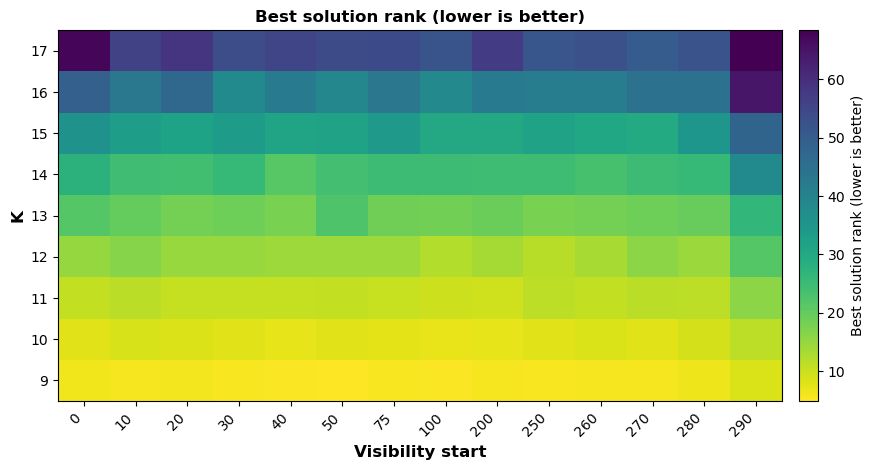

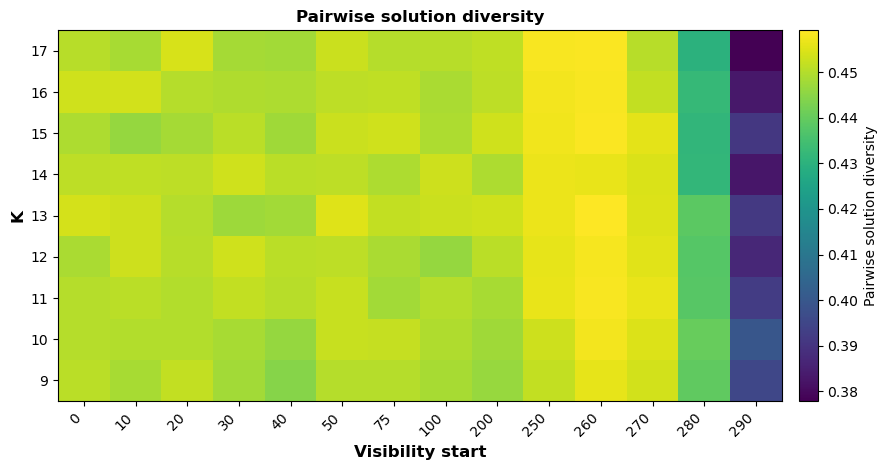

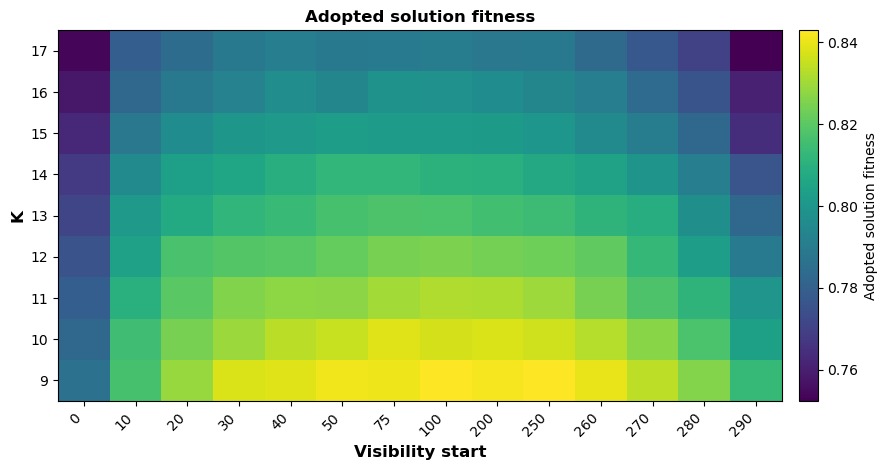

In [16]:
for dv, title, filename, cmap in [
    ('breakthrough_rank', 'Best solution rank (lower is better)', 'Best_solution_rank_heatmap_across_visibility_start_and_K.png', 'viridis_r'),
    ('pairwise_diversity', 'Pairwise solution diversity', 'Pairwise_diversity_heatmap_across_visibility_start_and_K.png', 'viridis'),
    ('adopted_solution_fitness', 'Adopted solution fitness', 'Adopted_solution_fitness_heatmap_across_visibility_start_and_K.png', 'viridis'),
]:
    values = np.ma.masked_invalid(data[dv].T)  # (K, start)
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap=cmap, origin='lower')
    ax.set_xticks(np.arange(len(visibility_start_list)))
    ax.set_xticklabels([f'{start:g}' for start in visibility_start_list], rotation=45, ha='right')
    ax.set_yticks(np.arange(len(K_list)))
    ax.set_yticklabels(K_list)
    ax.set_xlabel('Visibility start', fontweight='bold', fontsize=12)
    ax.set_ylabel('K', fontweight='bold', fontsize=12)
    ax.set_title(title, fontweight='bold', fontsize=12)
    fig.colorbar(image, ax=ax, label=title, pad=0.02)
    fig.tight_layout()
    # if save_figures:
    #     fig.savefig(figure_folder / filename, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()